<a href="https://colab.research.google.com/github/heitorabqg/datascientist/blob/master/fmcwSTFTGPU.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [17]:

%%writefile stft_fmcw.cu
#include <cstdio>
#include <cstdlib>
#include <cmath>
#include <vector>
#include <fstream>
#include <iomanip>
#include <cuda_runtime.h>
#include <cufft.h>

constexpr double C0 = 299792458.0;
constexpr double B = 100e6;
constexpr double TC = 200e-6;
constexpr double FS = 400e6;
constexpr int N = 80000;
constexpr double R = 1000.0;
constexpr int NF = 4096;
constexpr int HOP = 1024;

#ifndef M_PI
#define M_PI 3.14159265358979323846
#endif

#define CUDA(call) do { \
    cudaError_t e = (call); \
    if (e != cudaSuccess) { \
        fprintf(stderr, "CUDA: %s\n", cudaGetErrorString(e)); \
        return false; \
    } \
} while (0)

#define FFT(call) do { \
    cufftResult e = (call); \
    if (e != CUFFT_SUCCESS) { \
        fprintf(stderr, "cuFFT erro: %d\n", (int)e); \
        return false; \
    } \
} while (0)

__global__ void frame_signal(
    const cufftDoubleComplex *signal,
    cufftDoubleComplex *frames, int nframes)
{
    int idx = blockIdx.x * blockDim.x + threadIdx.x;
    int total = nframes * NF;
    if (idx >= total) return;

    int f = idx / NF;
    int i = idx % NF;
    int src = f * HOP + i;

    double w = 0.5 * (1.0 - cos(2.0 * M_PI * i / (NF - 1)));
    frames[idx].x = signal[src].x * w;
    frames[idx].y = signal[src].y * w;
}

__global__ void magnitude_kernel(
    const cufftDoubleComplex *spec, double *mag, int total)
{
    int i = blockIdx.x * blockDim.x + threadIdx.x;
    if (i >= total) return;
    mag[i] = hypot(spec[i].x, spec[i].y);
}

bool write_stft(
    const std::vector<cufftDoubleComplex>& signal,
    const char *filename)
{
    const int nframes = 1 + (N - NF) / HOP;
    const size_t count = (size_t)nframes * NF;

    cufftDoubleComplex *ds = nullptr, *df = nullptr, *dout = nullptr;
    double *dm = nullptr;

    CUDA(cudaMalloc(&ds, N * sizeof(*ds)));
    CUDA(cudaMalloc(&df, count * sizeof(*df)));
    CUDA(cudaMalloc(&dout, count * sizeof(*dout)));
    CUDA(cudaMalloc(&dm, count * sizeof(*dm)));
    CUDA(cudaMemcpy(ds, signal.data(), N * sizeof(*ds),
                    cudaMemcpyHostToDevice));

    cufftHandle plan;
    FFT(cufftPlan1d(&plan, NF, CUFFT_Z2Z, nframes));

    frame_signal<<<(count + 255) / 256, 256>>>(ds, df, nframes);
    CUDA(cudaGetLastError());
    FFT(cufftExecZ2Z(plan, df, dout, CUFFT_FORWARD));

    magnitude_kernel<<<(count + 255) / 256, 256>>>(dout, dm, count);
    CUDA(cudaGetLastError());
    CUDA(cudaDeviceSynchronize());

    std::vector<double> mag(count);
    CUDA(cudaMemcpy(mag.data(), dm, count * sizeof(double),
                    cudaMemcpyDeviceToHost));

    double maxmag = 0.0;
    for (double x : mag) if (x > maxmag) maxmag = x;

    std::ofstream out(filename);
    if (!out) {
        fprintf(stderr, "Nao foi possivel criar %s\n", filename);
        cufftDestroy(plan);
        cudaFree(ds); cudaFree(df); cudaFree(dout); cudaFree(dm);
        return false;
    }

    out << "time_us,frequency_MHz,magnitude_dB\n";
    out << std::fixed << std::setprecision(6);
    const double dfreq = FS / NF;

    for (int f = 0; f < nframes; ++f) {
        double time_us = (f * HOP + NF / 2.0) / FS * 1e6;
        for (int j = 0; j < NF; ++j) {
            int k = (j + NF / 2) % NF;
            double freq = (-FS / 2.0 + j * dfreq) / 1e6;
            double val = mag[(size_t)f * NF + k] / (maxmag + 1e-30);
            double db = 20.0 * log10(fmax(val, 1e-12));
            out << time_us << ',' << freq << ',' << db << '\n';
        }
    }

    out.close();
    cufftDestroy(plan);
    cudaFree(ds); cudaFree(df); cudaFree(dout); cudaFree(dm);
    printf("Gerado: %s (%d janelas)\n", filename, nframes);
    return true;
}

int main()
{
    int ngpu = 0;
    cudaError_t e = cudaGetDeviceCount(&ngpu);
    if (e != cudaSuccess || ngpu == 0) {
        fprintf(stderr, "GPU CUDA nao encontrada.\n");
        return 1;
    }

    cudaDeviceProp prop;
    cudaGetDeviceProperties(&prop, 0);
    printf("GPU: %s\n", prop.name);

    std::vector<cufftDoubleComplex> tx(N), rx(N), beat(N);
    const double slope = B / TC;
    const double delay = 2.0 * R / C0;

    for (int i = 0; i < N; ++i) {
        double t = i / FS;
        double ptx = M_PI * slope * t * t;
        tx[i] = {cos(ptx), sin(ptx)};

        if (t >= delay) {
            double tr = t - delay;
            double prx = M_PI * slope * tr * tr;
            rx[i] = {cos(prx), sin(prx)};

            // beat = Rx * conj(Tx)
            beat[i] = {
                rx[i].x * tx[i].x + rx[i].y * tx[i].y,
                rx[i].y * tx[i].x - rx[i].x * tx[i].y
            };
        } else {
            rx[i] = {0.0, 0.0};
            beat[i] = {0.0, 0.0};
        }
    }

    bool ok1 = write_stft(tx, "stft_tx.csv");
    bool ok2 = write_stft(rx, "stft_rx.csv");
    bool ok3 = write_stft(beat, "stft_beat.csv");

    return (ok1 && ok2 && ok3) ? 0 : 1;
}


Overwriting stft_fmcw.cu


In [18]:
!nvcc -O3 -std=c++17 stft_fmcw.cu -lcufft -o stft_fmcw && ./stft_fmcw

GPU: Tesla T4
Gerado: stft_tx.csv (75 janelas)
Gerado: stft_rx.csv (75 janelas)
Gerado: stft_beat.csv (75 janelas)


In [19]:
from pathlib import Path

for nome in ["stft_tx.csv", "stft_rx.csv", "stft_beat.csv"]:
    p = Path("/content") / nome
    print(nome, "OK" if p.exists() else "AUSENTE",
          f"({p.stat().st_size:,} bytes)" if p.exists() else "")

stft_tx.csv OK (10,253,522 bytes)
stft_rx.csv OK (10,242,025 bytes)
stft_beat.csv OK (10,249,584 bytes)


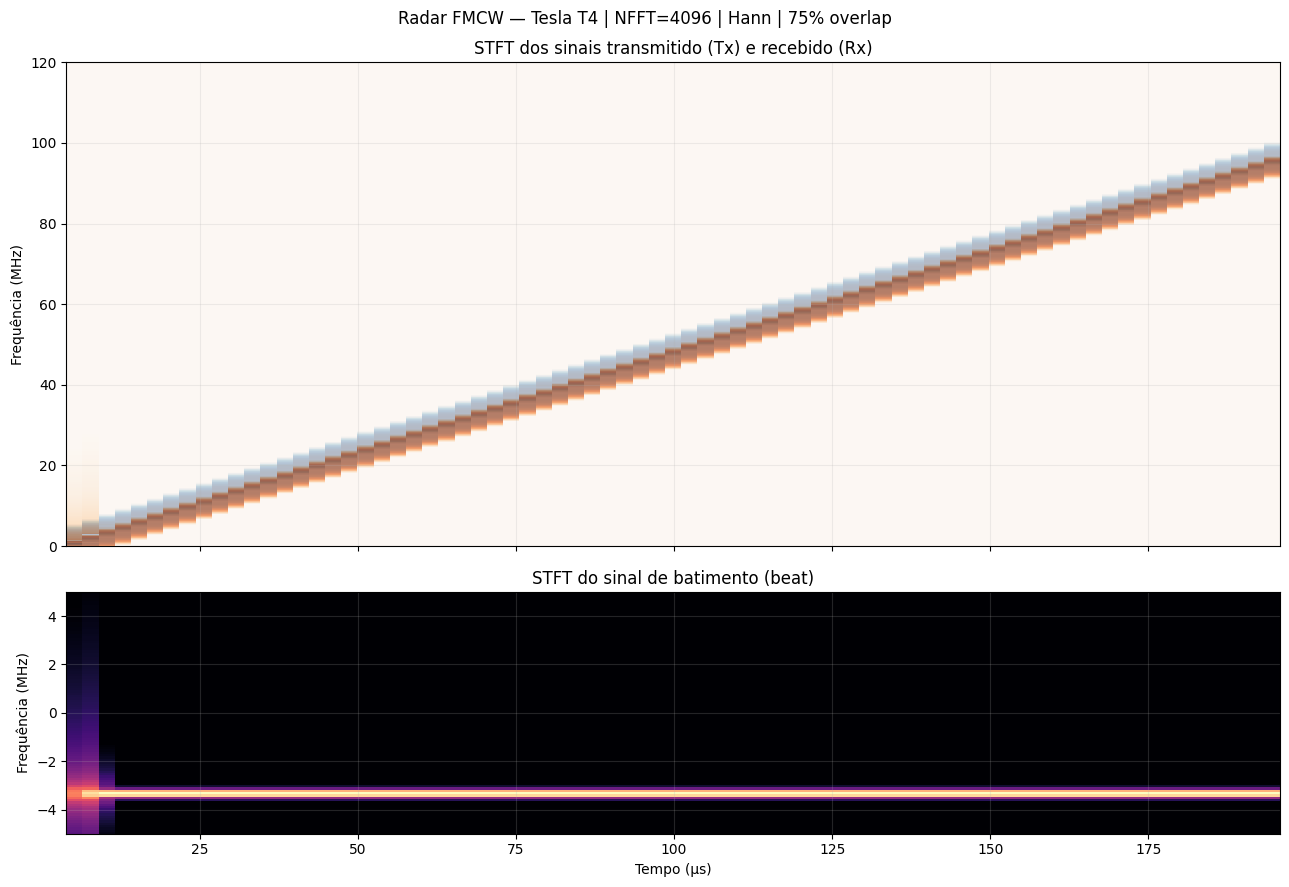

Gráfico salvo em /content/stft_tx_rx_beat.png


In [20]:
import pandas as pd
import matplotlib.pyplot as plt

def carregar(nome):
    return pd.read_csv("/content/" + nome)

def matriz(df):
    p = df.pivot(index="frequency_MHz",
                 columns="time_us",
                 values="magnitude_dB")
    p = p.sort_index().sort_index(axis=1)
    return p.columns.to_numpy(), p.index.to_numpy(), p.to_numpy()

tx = matriz(carregar("stft_tx.csv"))
rx = matriz(carregar("stft_rx.csv"))
beat = matriz(carregar("stft_beat.csv"))

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(13, 9), sharex=True,
    gridspec_kw={"height_ratios": [2, 1]}
)

ax1.pcolormesh(tx[0], tx[1], tx[2], shading="auto",
               cmap="Blues", vmin=-50, vmax=0, alpha=0.75)
ax1.pcolormesh(rx[0], rx[1], rx[2], shading="auto",
               cmap="Oranges", vmin=-50, vmax=0, alpha=0.60)
ax1.set_ylim(0, 120)
ax1.set_ylabel("Frequência (MHz)")
ax1.set_title("STFT dos sinais transmitido (Tx) e recebido (Rx)")
ax1.grid(alpha=0.2)

ax2.pcolormesh(beat[0], beat[1], beat[2], shading="auto",
               cmap="magma", vmin=-50, vmax=0)
ax2.set_ylim(-5, 5)
ax2.set_xlabel("Tempo (µs)")
ax2.set_ylabel("Frequência (MHz)")
ax2.set_title("STFT do sinal de batimento (beat)")
ax2.grid(alpha=0.2)

fig.suptitle("Radar FMCW — Tesla T4 | NFFT=4096 | Hann | 75% overlap")
fig.tight_layout()
fig.savefig("/content/stft_tx_rx_beat.png", dpi=180, bbox_inches="tight")
plt.show()

print("Gráfico salvo em /content/stft_tx_rx_beat.png")

In [21]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

arquivo = Path("/content/resultados_gpu.csv")

if not arquivo.exists():
    raise FileNotFoundError(
        "resultados_gpu.csv não encontrado. Verifique os arquivos em /content."
    )

df = pd.read_csv(arquivo)
print("Colunas disponíveis:", df.columns.tolist())
display(df.head())


Colunas disponíveis: ['NFFT', 'Frames', 'CPU_ms', 'GPU_ms', 'Speedup', 'CPU_peak_MHz', 'GPU_peak_MHz', 'Transfer_ms']


,NFFT,Frames,CPU_ms,GPU_ms,Speedup,CPU_peak_MHz,GPU_peak_MHz,Transfer_ms
0,256,1247,15.297322,0.505931,30.236005,3.125000,3.125000,0.260224
1,512,622,15.782705,0.523567,30.144580,3.125000,3.125000,0.260224
2,1024,309,16.282642,0.586977,27.739827,3.515625,3.515625,0.260224
3,2048,153,17.081219,0.623241,27.407105,3.320312,3.320312,0.260224
4,4096,75,17.565409,0.669397,26.240632,3.320312,3.320312,0.260224


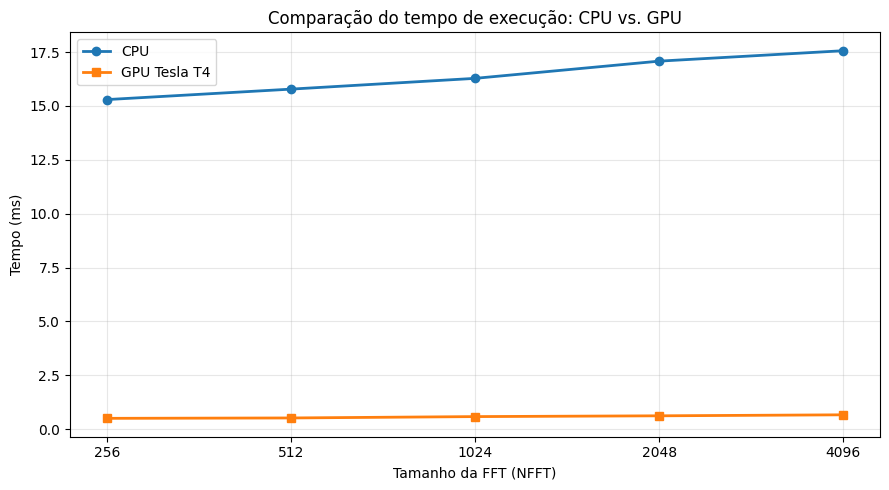

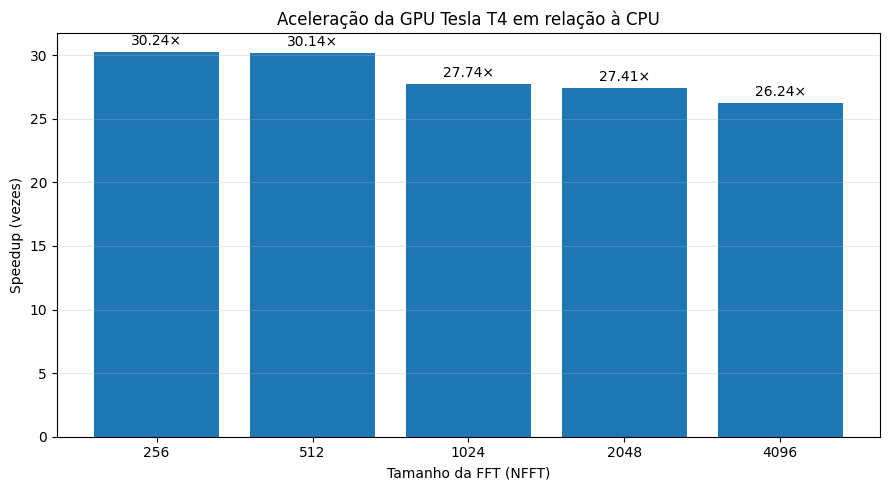

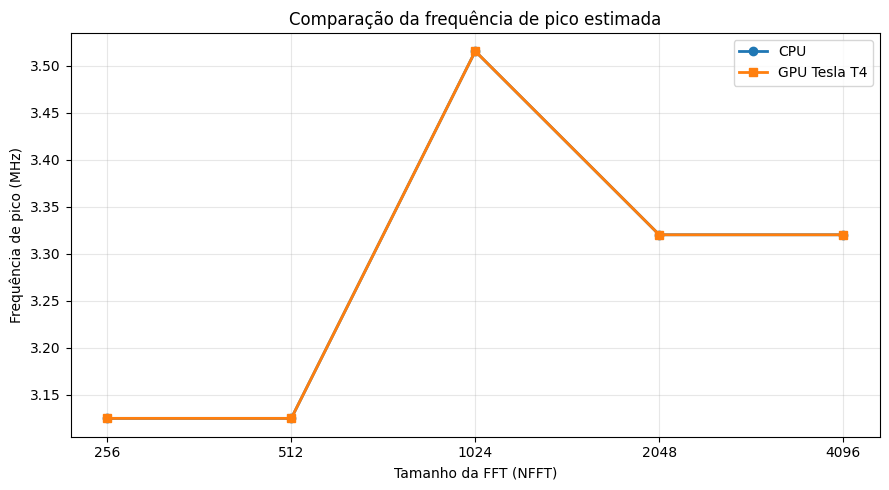


Figuras salvas em /content:
 - comparacao_tempos.png
 - comparacao_speedup.png
 - comparacao_frequencia.png


In [22]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

df = pd.read_csv("/content/resultados_gpu.csv")
df.columns = [c.strip() for c in df.columns]

# Normaliza os nomes para facilitar a identificação das colunas
def encontrar_coluna(opcoes):
    for coluna in df.columns:
        nome = coluna.lower().replace(" ", "").replace("_", "")
        if any(opcao in nome for opcao in opcoes):
            return coluna
    return None

c_nfft = encontrar_coluna(["nfft"])
c_cpu = encontrar_coluna(["cpu_ms", "cpums", "tempcpu"])
c_gpu = encontrar_coluna(["gpu_ms", "gp ums", "gp ums".replace(" ", ""), "tempgpu"])
c_speed = encontrar_coluna(["speedup", "aceleracao"])
c_cpu_peak = encontrar_coluna(["cpu_peak", "cpupeak"])
c_gpu_peak = encontrar_coluna(["gpu_peak", "gpupeak"])

# Compatibilidade com cabeçalhos separados por espaços
if c_cpu is None:
    c_cpu = encontrar_coluna(["cpu"])
if c_gpu is None:
    c_gpu = encontrar_coluna(["gpu"])

# Se o CSV usa tempos em milissegundos, os nomes podem ser CPU(ms)/GPU(ms)
if c_nfft is None or c_cpu is None or c_gpu is None:
    print("Cabeçalhos encontrados:", df.columns.tolist())
    raise ValueError(
        "Não identifiquei todas as colunas de NFFT, CPU e GPU. "
        "Envie os cabeçalhos exibidos acima para ajustar o código."
    )

df[c_nfft] = pd.to_numeric(df[c_nfft], errors="coerce")
df[c_cpu] = pd.to_numeric(df[c_cpu], errors="coerce")
df[c_gpu] = pd.to_numeric(df[c_gpu], errors="coerce")
df = df.dropna(subset=[c_nfft, c_cpu, c_gpu]).sort_values(c_nfft)

if c_speed is not None:
    df[c_speed] = pd.to_numeric(df[c_speed], errors="coerce")
else:
    df["Speedup_calculado"] = df[c_cpu] / df[c_gpu]
    c_speed = "Speedup_calculado"

saida = Path("/content")
x = df[c_nfft].astype(int).astype(str)

# 1. Comparação de tempo de execução
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(x, df[c_cpu], marker="o", linewidth=2, label="CPU")
ax.plot(x, df[c_gpu], marker="s", linewidth=2, label="GPU Tesla T4")
ax.set_xlabel("Tamanho da FFT (NFFT)")
ax.set_ylabel("Tempo (ms)")
ax.set_title("Comparação do tempo de execução: CPU vs. GPU")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(saida / "comparacao_tempos.png", dpi=180)
plt.show()

# 2. Speedup
fig, ax = plt.subplots(figsize=(9, 5))
barras = ax.bar(x, df[c_speed])
ax.set_xlabel("Tamanho da FFT (NFFT)")
ax.set_ylabel("Speedup (vezes)")
ax.set_title("Aceleração da GPU Tesla T4 em relação à CPU")
ax.grid(axis="y", alpha=0.3)
ax.bar_label(barras, fmt="%.2f×", padding=3)
fig.tight_layout()
fig.savefig(saida / "comparacao_speedup.png", dpi=180)
plt.show()

# 3. Frequência de pico estimada pela FFT
if c_cpu_peak is not None and c_gpu_peak is not None:
    df[c_cpu_peak] = pd.to_numeric(df[c_cpu_peak], errors="coerce")
    df[c_gpu_peak] = pd.to_numeric(df[c_gpu_peak], errors="coerce")

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(x, df[c_cpu_peak], marker="o", linewidth=2, label="CPU")
    ax.plot(x, df[c_gpu_peak], marker="s", linewidth=2, label="GPU Tesla T4")
    ax.set_xlabel("Tamanho da FFT (NFFT)")
    ax.set_ylabel("Frequência de pico (MHz)")
    ax.set_title("Comparação da frequência de pico estimada")
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(saida / "comparacao_frequencia.png", dpi=180)
    plt.show()
else:
    print(
        "Colunas de frequência de pico não encontradas; "
        "o gráfico de frequência não foi recriado."
    )

print("\nFiguras salvas em /content:")
for nome in [
    "comparacao_tempos.png",
    "comparacao_speedup.png",
    "comparacao_frequencia.png"
]:
    p = saida / nome
    if p.exists():
        print(f" - {nome}")
